In [45]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torch.utils.data import Dataset
import torch.optim as optim
import matplotlib.pyplot as plt

In [46]:
class CustomDataset(Dataset):
    def __init__(self, input_data, output_data):
        self.input_data = input_data
        self.output_data = output_data
        
    def __len__(self):
        return self.input_data.shape[0]

    def __getitem__(self, idx):
        x = self.input_data[idx, :]
        y = self.output_data[idx]
        return x, y

In [47]:
class TwoLayerNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super(TwoLayerNN, self).__init__()
        #self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc1 = nn.Linear(input_size, output_size)
        #self.fc2 = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        #x = F.relu(self.fc1(x))  # Apply ReLU activation function to the first layer
        x = self.fc1(x)
        #x = self.fc2(x)          # Output layer, no activation function applied
        return x

In [4]:
def loss_function(y_hat, y, model, lambda_2, lambda_3):
    """
    Computes the negative variational lower bound loss term of the VAE (refer to
    formulation in notebook).

    Inputs:
    - x_hat: Reconstruced input data of shape (N, 1, H, W)
    - x: Input data for this timestep of shape (N, 1, H, W)
    - mu: Matrix representing estimated posterior mu (N, Z), with Z latent space
      dimension
    - logvar: Matrix representing estimated variance in log-space (N, Z), with Z
      latent space dimension

    Returns:
    - loss: Tensor containing the scalar loss for the negative variational
      lowerbound
    """
    loss = None

    l1 = nn.functional.mse_loss(y_hat, y, reduction = 'sum')
    l2 = 0
    l3 = 0
    
    for p in model.parameters():
        l2 = l2 + p.abs().sum()
    
    for p in model.parameters():
        if len(p.shape) == 1:
            continue
        l3 = l3 + ((1*(p.abs() > 0)).diff().abs()).sum()
    
    loss = l1 + lambda_2*l2 + lambda_3*l3

    ###############################################################################
    #                            END OF YOUR CODE                                 #
    ###############################################################################
    return loss

In [5]:
def train_model(epoch, model, train_loader, lambda_2, lambda_3):
    """
    Train a VAE or CVAE!

    Inputs:
    - epoch: Current epoch number
    - model: VAE model object
    - train_loader: PyTorch Dataloader object that contains our training data
    - cond: Boolean value representing whether we're training a VAE or
    Conditional VAE
    """
    model.train()
    train_loss = 0
    #num_classes = 10
    loss = None
    optimizer = optim.Adam(model.parameters(), lr=1e-2)
    for batch_idx, data in enumerate(train_loader):
        #data = data.to(device='cpu')
        (x, y) = data
        y_hat = model(x)
        optimizer.zero_grad()
        loss = loss_function(y_hat, y, model, lambda_2, lambda_3)
        loss.backward()
        train_loss += loss.data
        optimizer.step()
    #print("Train Epoch: {} \tLoss: {:.6f}".format(epoch, loss.data))

In [6]:
import os
import cv2
import pandas as pd
import numpy as np

import torchvision.transforms as T
#image = Image.open(GOOGLE_DRIVE_PATH + '/001_01_01_010_00_crop_128.png')
#image = image.convert("RGB")
#trans_img = T.Resize(size=224)(image)
#transform = transforms.Compose([transforms.ToTensor()])
transform = T.Compose([T.ToTensor()])
#image_tensor = transform(trans_img).to(device)
#plt.imshow(np.array(torch.permute(image_tensor, (1, 2, 0))))

In [25]:
path = '/Users/eochoa/Downloads/multi_PIE_crop_128/'
folders = os.listdir(path)
names = list([os.listdir(path+f) for f in folders if f != '.DS_Store'])
names = list(np.array(names).flat)
names_ = [n[:3] + '/' + n for n in names]
len(names_)

129480

In [8]:
#np.array(folders)[~ (np.array(folders) == '.DS_Store')][np.array([len(n)==0 for n in names])] 213

In [44]:
views = list(set([n.split('_')[3] for n in names]))
for v in views[:2]:
    images = [transform(cv2.imread(os.path.join(path, x)))[None,:] for i, x in enumerate(names_) if names[i][10:13] == v]
    labels = [int(n.split('_')[0]) for n in names if n[10:13] == v]

    input_data = torch.concatenate(images,0)
    output_data = torch.tensor(labels)

    data = CustomDataset(input_data, output_data)
    torch.save(data, 'data_'+v+'.pt')

['041',
 '050',
 '240',
 '190',
 '051',
 '110',
 '090',
 '010',
 '130',
 '120',
 '200',
 '080',
 '140']

In [3]:
data = torch.load('data.pt')

In [6]:
data.input_data.shape

torch.Size([1000, 100])

In [14]:
# Example usage:
input_size = 100
hidden_size = 20
output_size = 1
N = 1000

input_data = torch.randn(N, input_size)  # Random input tensor of shape (1, input_size)
theta = torch.randn(input_size, 1)  # Random input tensor of shape (1, input_size)
output_data = input_data @ theta + .1*torch.randn(N, 1)

In [15]:
theta[20:50,:] = 0
theta.flatten()

tensor([ 0.4907,  0.4676, -0.7769,  0.5561, -1.1055,  0.6262,  0.8601, -0.1364,
         0.7731,  0.7583,  0.0253,  0.5607, -0.4465, -0.2402,  0.5430, -1.1082,
        -0.7017,  0.5967,  0.6617, -1.4904,  0.0000,  0.0000,  0.0000,  0.0000,
         0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
         0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
         0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
         0.0000,  0.0000,  0.4971,  0.2342,  0.9840,  0.9979,  0.2207, -0.2193,
        -0.6698, -1.2060, -0.7757, -0.2621,  0.9702, -1.5465,  0.4130,  0.4545,
         0.1386,  0.3637, -0.0841,  0.5564, -0.7623, -0.7489, -1.2515,  0.3874,
        -0.6978, -1.5468, -1.6687,  0.4630,  0.3849, -0.1452,  0.7793,  3.2225,
         0.3587, -0.1977,  1.4040, -0.2449,  0.0152, -0.1249,  0.8802, -1.3436,
        -1.4437, -0.4397,  0.0747,  0.4418,  0.0084, -1.9619, -0.4247, -1.4472,
        -0.4399,  0.8458, -1.6442,  0.61

In [17]:
batch_size = 100
data = CustomDataset(input_data, output_data)
loader_train = DataLoader(data, batch_size=batch_size,shuffle=True, drop_last=True)

torch.save(data, 'data.pt')

In [4]:
data = torch.load('data.pt')

In [228]:
# Instantiate the model
model = TwoLayerNN(input_size, hidden_size, output_size)

lambda_2 = 5
lambda_3 = 1

num_epochs = 10000
for epoch in range(0, num_epochs):
    _ = train_model(epoch, model, loader_train, lambda_2, lambda_3)
    
model = model.eval()
with torch.no_grad():
    y_hat = model(input_data).flatten()
    
((y_hat - output_data.flatten()) ** 2).sum()

tensor(87.9242)

In [227]:
for p in model.parameters():   
    print(torch.round(p, decimals=2))

tensor([[-0.3600,  0.1400, -0.1700, -0.3500, -0.6700,  2.3000,  1.6300, -0.5500,
          0.1700,  0.0300,  1.6400, -0.3800, -1.4500,  1.5700, -0.9500,  0.9900,
         -0.2400,  1.0100, -0.4800,  0.1800, -0.5500,  1.9500, -0.0500,  0.2500,
         -0.0400,  0.1000, -0.1500, -0.3700, -0.6000, -0.9100, -0.4200,  1.6200,
          0.1400,  0.3100, -0.3400, -0.0400,  0.4700, -1.0700,  1.0600,  0.8600,
         -0.6400, -1.2700,  0.9400,  0.0500,  0.9400,  0.6900, -0.4000,  0.4700,
         -0.9500,  0.7100, -1.5300,  0.0600, -1.5600,  1.2200, -0.3800,  0.5200,
          0.3400,  0.8800,  0.0900,  0.9000,  2.5500,  1.1600,  1.8300,  0.4200,
         -1.9800,  0.1300, -0.1500, -0.4600, -2.5000, -1.5400, -0.4400, -1.0700,
         -1.7000, -0.0500, -0.9100, -0.8000,  0.1600,  0.6200, -0.5700,  1.4900,
          1.9600, -0.7100, -0.4000,  2.1500,  0.4500, -1.2200, -0.7200, -0.4000,
          1.2000, -1.1900,  0.3300,  1.1700, -1.6000,  0.0900,  1.3300, -1.9900,
         -0.0500, -1.2800, -

In [223]:
theta.flatten()

tensor([-0.3653,  0.1347, -0.1731, -0.3677, -0.6802,  2.3046,  1.6376, -0.5590,
         0.1820,  0.0131,  1.6307, -0.3712, -1.4551,  1.5765, -0.9479,  1.0107,
        -0.2333,  0.9990, -0.4754,  0.1766,  0.0000,  0.0000,  0.0000,  0.0000,
         0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
         0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
         0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
         0.0000,  0.0000, -1.5293,  0.0620, -1.5580,  1.2429, -0.4021,  0.5312,
         0.3430,  0.8885,  0.0972,  0.9158,  2.5402,  1.1574,  1.8316,  0.4178,
        -1.9870,  0.1428, -0.1612, -0.4815, -2.4994, -1.5318, -0.4326, -1.0664,
        -1.7127, -0.0576, -0.9255, -0.7846,  0.1612,  0.6144, -0.5742,  1.4858,
         1.9560, -0.7149, -0.4072,  2.1738,  0.4385, -1.2336, -0.7289, -0.4056,
         1.2087, -1.2059,  0.3420,  1.1637, -1.6026,  0.1044,  1.3229, -1.9874,
        -0.0458, -1.2878, -0.5785, -1.88

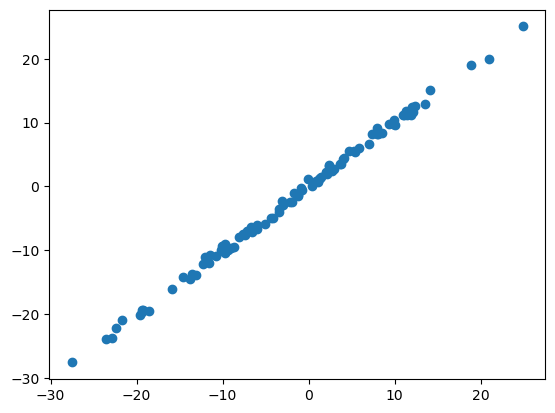

In [141]:
plt.scatter(y_hat, output_data.flatten())